In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/retail_inventory_cleaned.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Dataset shape:", df.shape)
print(df.columns.tolist())
display(df.head())

Dataset shape: (73100, 14)
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Year', 'Month', 'DayOfWeek', 'Revenue']


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Year,Month,DayOfWeek,Revenue
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,2022,1,5,4254.50
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,2022,1,5,9451.50
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,2022,1,5,1819.35
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,2022,1,5,1995.92
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,2022,1,5,1030.96


In [2]:
columns_to_check = [
    "Price",
    "Units Sold",
    "Inventory Level",
    "Demand Forecast"
]

display(df[columns_to_check].describe().T)
print(df[columns_to_check].isnull().sum())

,count,mean,std,min,25%,50%,75%,max
Price,73100.0,55.135108,26.021945,10.00,32.65,55.050,77.8600,100.00
Units Sold,73100.0,136.464870,108.919406,0.00,49.00,107.000,203.0000,499.00
Inventory Level,73100.0,274.469877,129.949514,50.00,162.00,273.000,387.0000,500.00
Demand Forecast,73100.0,141.494720,109.254076,-9.99,53.67,113.015,208.0525,518.55


Price              0
Units Sold         0
Inventory Level    0
Demand Forecast    0
dtype: int64


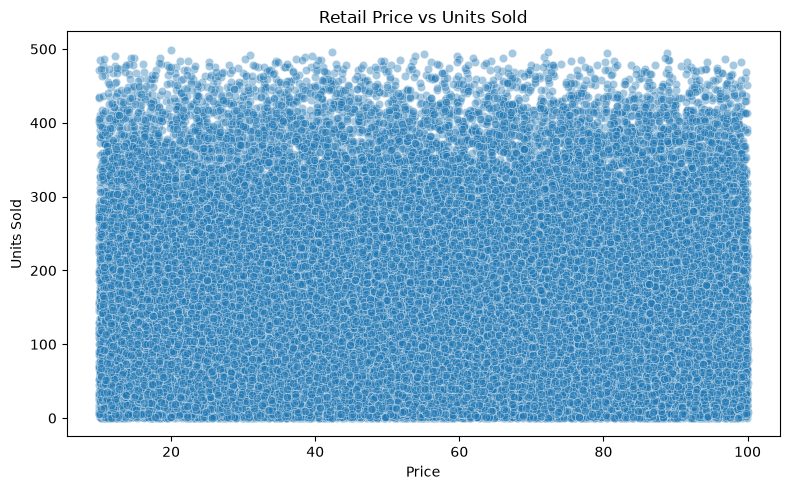

In [3]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Price",
    y="Units Sold",
    alpha=0.4
)

plt.title("Retail Price vs Units Sold")
plt.xlabel("Price")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

In [4]:
df["Price_Group"] = pd.qcut(
    df["Price"],
    q=5,
    duplicates="drop"
)

price_summary = df.groupby(
    "Price_Group", observed=True
)["Units Sold"].agg(
    ["mean", "median", "count"]
).round(2)

display(price_summary)

,mean,median,count
Price_Group,,,
"(9.999, 28.218]",135.67,107.0,14620
"(28.218, 46.166]",137.65,108.0,14620
"(46.166, 63.97]",135.60,106.0,14629
"(63.97, 82.32]",136.63,108.0,14612
"(82.32, 100.0]",136.77,108.0,14619


In [5]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek

features = [
    "Price",
    "Inventory Level",
    "Year",
    "Month",
    "DayOfWeek",
    "Category",
    "Region",
    "Product ID",
    "Store ID"
]

target = "Units Sold"

model_df = df[features + [target] + ["Date"]].copy()
model_df = model_df.dropna()

print("Rows available for modeling:", len(model_df))
display(model_df.head())

Rows available for modeling: 73100


,Price,Inventory Level,Year,Month,DayOfWeek,Category,Region,Product ID,Store ID,Units Sold,Date
0,33.50,231,2022,1,5,Groceries,North,P0001,S001,127,2022-01-01
1,63.01,204,2022,1,5,Toys,South,P0002,S001,150,2022-01-01
2,27.99,102,2022,1,5,Toys,West,P0003,S001,65,2022-01-01
3,32.72,469,2022,1,5,Toys,North,P0004,S001,61,2022-01-01
4,73.64,166,2022,1,5,Electronics,East,P0005,S001,14,2022-01-01


In [6]:
model_df = model_df.sort_values("Date").reset_index(drop=True)

split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Testing period:", test_df["Date"].min(), "to", test_df["Date"].max())

Training rows: 58480
Testing rows: 14620
Training period: 2022-01-01 00:00:00 to 2023-08-08 00:00:00
Testing period: 2023-08-08 00:00:00 to 2024-01-01 00:00:00


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

numeric_features = [
    "Price",
    "Inventory Level",
    "Year",
    "Month",
    "DayOfWeek"
]

categorical_features = [
    "Category",
    "Region",
    "Product ID",
    "Store ID"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

model.fit(X_train, y_train)

print("Baseline model training completed!")

Baseline model training completed!


In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

MAE: 69.51
RMSE: 89.36
R² Score: 0.318


In [9]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

dummy_predictions = dummy.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_predictions)

print("Simple baseline MAE:", round(dummy_mae, 2))
print("Random Forest MAE:", round(mae, 2))

Simple baseline MAE: 88.81
Random Forest MAE: 69.51


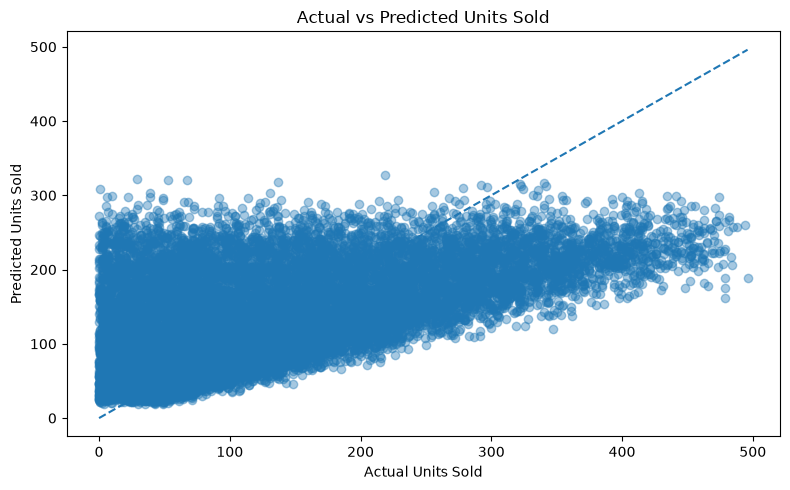

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions, alpha=0.4)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.title("Actual vs Predicted Units Sold")
plt.xlabel("Actual Units Sold")
plt.ylabel("Predicted Units Sold")
plt.tight_layout()
plt.show()

In [11]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(model, model_dir / "baseline_demand_model.joblib")

print("Model saved successfully!")

Model saved successfully!
